In [1]:
# Add any additional libraries or submodules below

# Data libraries
import pandas as pd
import numpy as np

# Plotting libraries
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn modules
import sklearn

In [2]:
# Load data  
df_avg = pd.read_csv("avg_river_levels.csv")
df_min = pd.read_csv("min_river_levels.csv")
df_max = pd.read_csv("max_river_levels.csv")
df_locs = pd.read_csv("monitoring_locations.csv")
# display(df_avg.head())

In [3]:
# Data preprocessing
def prepare_cluster(df):

    date_cols = df.columns[3:]

    data = df[date_cols].apply(
        pd.to_numeric, errors="coerce"
    )

    # Replace observations with |value| > 40 with NaN
    data = data.mask(data.abs() > 40)

    data.columns = pd.to_datetime(date_cols, dayfirst=True)

    data = data.sort_index(axis=1)

    all_dates = pd.date_range(
        start=data.columns.min(),
        end=data.columns.max(),
        freq="D"
    )

    data = data.reindex(columns=all_dates)

    # Remove the first 908 dates
    data = data.iloc[:, 908:]

    return data.T

# Prepare the data for our model
avg = prepare_cluster(df_avg)
minimum = prepare_cluster(df_min)
maximum = prepare_cluster(df_max)

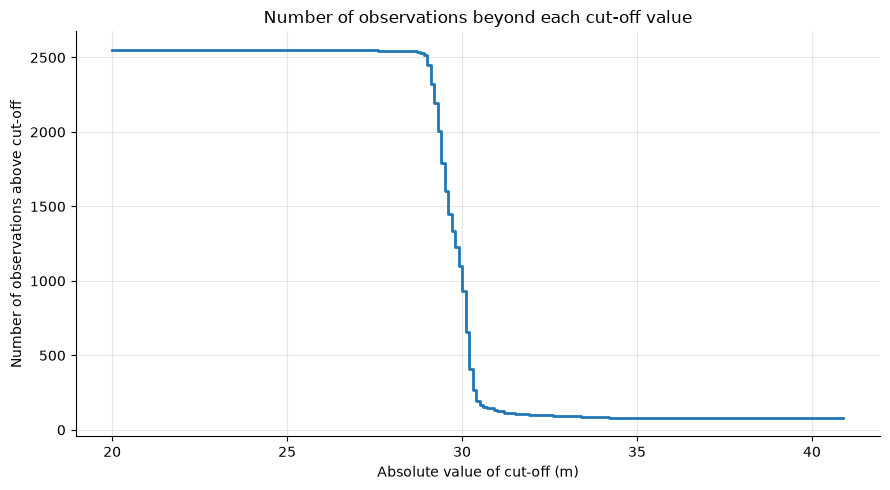

In [4]:
# Identifying a sutable choice for cutt=off
X_avg = df_avg.drop(columns = ['County', 'Station_Name', 'Observation_ID'])
X_min = df_min.drop(columns = ['County', 'Station_Name', 'Observation_ID'])
X_max = df_max.drop(columns = ['County', 'Station_Name', 'Observation_ID'])
cutoff_in_m = np.arange(20, 41, 0.1)
abs_avg = np.abs(np.asarray(X_avg))

counts = [(abs_avg > c).sum() for c in cutoff_in_m]

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(cutoff_in_m, counts, linewidth=2, drawstyle="steps-post")
ax.set_xlabel("Absolute value of cut-off (m)")
ax.set_ylabel("Number of observations above cut-off")
ax.set_title("Number of observations beyond each cut-off value")
ax.grid(alpha=0.3)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

In [5]:
from numpy.lib.stride_tricks import sliding_window_view
# Creating a new df that can be used to predict whether or not a flood will happen on the next day, based on the water levels of the preceding seven days.
def valid_7day(df):
    """
    Inputs: The preprocessed data frame of water levels
    ---
    Outputs: new df outlining all valid 7 day periods with next day also valid, also reports associated ID and week start date
    
    """
    numeric_vals = df.to_numpy(float) # Extracts the data in df
    dates = df.index                  # Extracts the day lables

    period = sliding_window_view(numeric_vals, 8, axis=0)  
    # np function which runs through data highlighting every 8 day window
    # period is shaped as [the day, the ID, the 8 day window of readings]
    # (Note: for the the 8 day window of readings argument we are dating 'forwards'- which is why we get less days than in the original df, removes last 7 days of data set)]
    
    nan_present = ~np.isnan(period).any(axis=2) # goes through all period and marks False where NaN present 
    # (Note: ~ flips True to False and vise versa so we make NaN as False)

    # We name ID and start date for the nan_present that have NO falses (ie ID and start date for the 8 day periods with no NaN in them)
    ID_name, date_start_name = np.nonzero(nan_present.T)
    valid_periods = period[date_start_name, ID_name, :] # indexing these valid periods 

    # Classifying a flood event
    flood_event =  valid_periods[:, 7] > 10 # We need to decide on this threshold

    # Created df for output
    valid_7day = pd.DataFrame({
        "ID": df.columns[ID_name],
        "Week starting": dates[date_start_name],
        "Day 1": valid_periods[:, 0],
        "Day 2": valid_periods[:, 1],
        "Day 3": valid_periods[:, 2],
        "Day 4": valid_periods[:, 3],
        "Day 5": valid_periods[:, 4],
        "Day 6": valid_periods[:, 5],
        "Day 7": valid_periods[:, 6],
        "Next Day": valid_periods[:, 7],
        "Flood Event Occurd": flood_event
    })
    
    return valid_7day

# Testing it works
display(valid_7day(avg))
print(f"Have we successfully got no NaNs? {valid_7day(avg).shape == valid_7day(avg).dropna().shape}")

display(valid_7day(minimum))
print(f"Have we successfully got no NaNs? {valid_7day(minimum).shape == valid_7day(minimum).dropna().shape}")

display(valid_7day(maximum))
print(f"Have we successfully got no NaNs? {valid_7day(maximum).shape == valid_7day(maximum).dropna().shape}")

# (Note: the dimensions of these df will be different since the cut-off range will effect min and max data differently)

# Number of flood events
print(f"avg: {valid_7day(avg)["Flood Event Occurd"].value_counts()}")
print(f"minimum: {valid_7day(minimum)["Flood Event Occurd"].value_counts()}")
print(f"maximum: {valid_7day(maximum)["Flood Event Occurd"].value_counts()}")

,ID,Week starting,Day 1,Day 2,Day 3,Day 4,Day 5,Day 6,Day 7,Next Day,Flood Event Occurd
0,0,2017-03-31,0.221,0.221,0.220,0.212,0.208,0.204,0.202,0.199,False
1,0,2017-04-01,0.221,0.220,0.212,0.208,0.204,0.202,0.199,0.197,False
2,0,2017-04-02,0.220,0.212,0.208,0.204,0.202,0.199,0.197,0.195,False
3,0,2017-04-03,0.212,0.208,0.204,0.202,0.199,0.197,0.195,0.195,False
4,0,2017-04-04,0.208,0.204,0.202,0.199,0.197,0.195,0.195,0.193,False
...,...,...,...,...,...,...,...,...,...,...,...
1166176,391,2026-09-27,0.713,0.530,0.471,0.685,0.495,0.708,0.557,0.485,False
1166177,391,2026-09-28,0.530,0.471,0.685,0.495,0.708,0.557,0.485,0.505,False
1166178,391,2026-09-29,0.471,0.685,0.495,0.708,0.557,0.485,0.505,0.485,False
1166179,391,2026-09-30,0.685,0.495,0.708,0.557,0.485,0.505,0.485,0.453,False


Have we successfully got no NaNs? True


,ID,Week starting,Day 1,Day 2,Day 3,Day 4,Day 5,Day 6,Day 7,Next Day,Flood Event Occurd
0,0,2017-03-31,0.219,0.216,0.214,0.209,0.204,0.201,0.200,0.197,False
1,0,2017-04-01,0.216,0.214,0.209,0.204,0.201,0.200,0.197,0.195,False
2,0,2017-04-02,0.214,0.209,0.204,0.201,0.200,0.197,0.195,0.194,False
3,0,2017-04-03,0.209,0.204,0.201,0.200,0.197,0.195,0.194,0.193,False
4,0,2017-04-04,0.204,0.201,0.200,0.197,0.195,0.194,0.193,0.191,False
...,...,...,...,...,...,...,...,...,...,...,...
1166506,391,2026-09-27,0.460,0.490,0.460,0.460,0.470,0.470,0.500,0.480,False
1166507,391,2026-09-28,0.490,0.460,0.460,0.470,0.470,0.500,0.480,0.480,False
1166508,391,2026-09-29,0.460,0.460,0.470,0.470,0.500,0.480,0.480,0.460,False
1166509,391,2026-09-30,0.460,0.470,0.470,0.500,0.480,0.480,0.460,0.450,False


Have we successfully got no NaNs? True


,ID,Week starting,Day 1,Day 2,Day 3,Day 4,Day 5,Day 6,Day 7,Next Day,Flood Event Occurd
0,0,2017-03-31,0.223,0.231,0.228,0.214,0.211,0.207,0.204,0.201,False
1,0,2017-04-01,0.231,0.228,0.214,0.211,0.207,0.204,0.201,0.198,False
2,0,2017-04-02,0.228,0.214,0.211,0.207,0.204,0.201,0.198,0.197,False
3,0,2017-04-03,0.214,0.211,0.207,0.204,0.201,0.198,0.197,0.197,False
4,0,2017-04-04,0.211,0.207,0.204,0.201,0.198,0.197,0.197,0.195,False
...,...,...,...,...,...,...,...,...,...,...,...
1166359,391,2026-09-27,1.410,0.600,0.490,1.260,0.530,1.370,0.690,0.500,False
1166360,391,2026-09-28,0.600,0.490,1.260,0.530,1.370,0.690,0.500,0.530,False
1166361,391,2026-09-29,0.490,1.260,0.530,1.370,0.690,0.500,0.530,0.520,False
1166362,391,2026-09-30,1.260,0.530,1.370,0.690,0.500,0.530,0.520,0.460,False


Have we successfully got no NaNs? True
avg: Flood Event Occurd
False    1163750
True        2431
Name: count, dtype: int64
minimum: Flood Event Occurd
False    1164087
True        2424
Name: count, dtype: int64
maximum: Flood Event Occurd
False    1163787
True        2577
Name: count, dtype: int64


Flood Event Occurd
False    99.70257
True      0.29743
Name: proportion, dtype: float64
Flood Event Occurd
False    99.999143
True      0.000857
Name: proportion, dtype: float64
Accuracy: 0.9999942833459576
Recall: 0.6666666666666666
Precision: 0.6666666666666666
F1-score: 0.6666666666666666


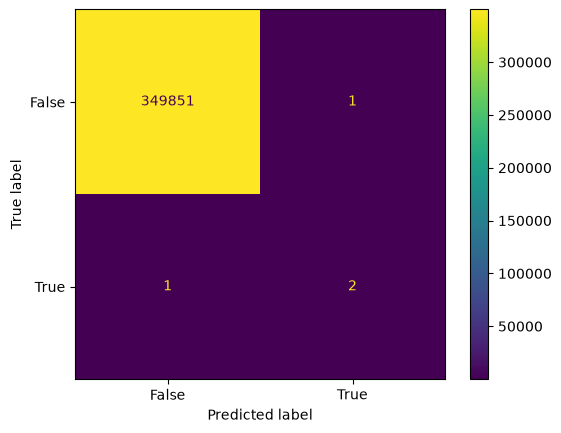

In [6]:
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score
from sklearn import preprocessing

# Splitting the preprocessed data
X = valid_7day(avg).iloc[:,[2,3,4,5,6,7,8]] # only 7 day period
y = valid_7day(avg).iloc[:, 10] # the next day after 7 day period

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=False,
                                                    test_size = 0.3, random_state=0)
# print(X_train)
# print(X_test)
# print(y_train) 
# print(y_test)

# creating a pipe using the make_pipeline method
pipe = make_pipeline(LogisticRegression(random_state=42, C=np.inf))

#fitting data into the model
pipe.fit(X_train, y_train)

# predicting values
y_pred = pipe.predict(X_test)

# Check the proportion of defaults in both train and test data sets 
print(pd.Series(y_train).value_counts(normalize=True)*100)
print(pd.Series(y_test).value_counts(normalize=True)*100)
# (Note: data is HIGHLY imbalances, had to set 70/30... need to decide how to deal with data imbalance)

# Compute metrics
print("Accuracy:", accuracy_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("F1-score:", f1_score(y_test, y_pred))

ConfusionMatrixDisplay.from_estimator(pipe.fit(X_train, y_train), X_test, y_test)
plt.show()